Project 1: Company Expense & Budget Variance Analysis
The Goal: Help a company's finance department find out where they are overspending and which
departments are busting their budgets.
●
●
●
What you will do:
○
Load monthly department budget sheets and actual expense CSVs.
○
Use Pandas to merge the files and calculate the absolute and percentage variance
(Budget vs. Actual).
○
Group data by department and expense category (e.g., Marketing, Travel, Software).
○
Use Seaborn to create a horizontal bar chart showing the top 10 areas with the worst
overspending.
Resume Value: Demonstrates clear, practical corporate financial literacy.
Dataset: Look for "Corporate Expense Data" on Kaggle, or generate a clean mock sheet in
Excel.

1. Import Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Visualization Settings
sns.set_style("whitegrid")

# Display Settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

2. Load Dataset

In [3]:
df = pd.read_csv("Budget_vs_Actual_Data.csv")

3. Basic Data Exploration

In [4]:
df.head()

,Date,Department,Category,Region,Budget Amount,Actual Amount,Payment Method,Transaction ID
0,2023/05/11 00:00:00,Sales,Travel,North,126096,43048,Card,TXN100000
1,2023/11/11 00:00:00,Marketing,Salaries,East,19702,87896,Bank Transfer,TXN100001
2,2021/05/02 00:00:00,IT,Training,Central,108523,103632,Card,TXN100002
3,2022/04/12 00:00:00,Marketing,Salaries,North,114711,105574,Cash,TXN100003
4,2021/11/27 00:00:00,Sales,Utilities,Central,121895,64314,UPI,TXN100004


In [5]:
df.tail()

,Date,Department,Category,Region,Budget Amount,Actual Amount,Payment Method,Transaction ID
10005,2022/04/18 00:00:00,Marketing,Marketing,South,23229,89695,Bank Transfer,TXN108517
10006,2021/05/12 00:00:00,Sales,Infrastructure,South,28919,65335,Card,TXN102041
10007,2021/08/23 00:00:00,Sales,Utilities,East,82957,72156,UPI,TXN101989
10008,2022/01/03 00:00:00,Finance,Infrastructure,North,68546,91058,Cash,TXN101933
10009,2023/01/19 00:00:00,Sales,Travel,Central,102272,114341,Card,TXN109984


In [6]:
print("Rows and Columns:", df.shape)

Rows and Columns: (10010, 8)


In [7]:
df.columns

Index(['Date', 'Department', 'Category', 'Region', 'Budget Amount',
       'Actual Amount', 'Payment Method', 'Transaction ID'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10010 entries, 0 to 10009
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Date            10010 non-null  object
 1   Department      10009 non-null  object
 2   Category        10009 non-null  object
 3   Region          10007 non-null  object
 4   Budget Amount   10010 non-null  int64 
 5   Actual Amount   10010 non-null  int64 
 6   Payment Method  10010 non-null  object
 7   Transaction ID  10007 non-null  object
dtypes: int64(2), object(6)
memory usage: 625.8+ KB


4. Statistical Summary

Numerical columns

In [10]:
df.describe()

,Budget Amount,Actual Amount
count,10010.000000,10010.000000
mean,79531.584316,89031.239261
std,40490.798172,46947.492216
min,10005.000000,8002.000000
25%,44379.000000,48570.250000
50%,79515.500000,89188.000000
75%,114575.250000,130586.000000
max,149992.000000,169973.000000


Categorical Columns

In [11]:
df.describe(include='object')

,Date,Department,Category,Region,Payment Method,Transaction ID
count,10010,10009,10009,10007,10010,10007
unique,1095,6,6,5,4,9997
top,2022/01/22 00:00:00,HR,Travel,Central,UPI,TXN104962
freq,20,1728,1745,2048,2556,2


5. Data Quality Check

In [12]:
df.isnull().sum()

Date              0
Department        1
Category          1
Region            3
Budget Amount     0
Actual Amount     0
Payment Method    0
Transaction ID    3
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(10)

6. Feature Engineering

Convert Date Column

In [14]:
df['Date'] = pd.to_datetime(df['Date'])

Extract Month

In [15]:
df['Month'] = df['Date'].dt.month_name()

Extract Year

In [16]:
df['Year'] = df['Date'].dt.year

Variance

In [17]:
df['Variance'] = df['Actual Amount'] - df['Budget Amount']

Variance Percentage

In [18]:
df['Variance %'] = (
    df['Variance'] / df['Budget Amount']
) * 100

Overspending Status

In [19]:
df['Status'] = np.where(
    df['Actual Amount'] > df['Budget Amount'],
    'Over Budget',
    'Within Budget'
)

7. Business EDA KPI Analysis

In [20]:
print("Total Budget:", df['Budget Amount'].sum())
print("Total Actual:", df['Actual Amount'].sum())
print("Total Variance:", df['Variance'].sum())

Total Budget: 796111159
Total Actual: 891202705
Total Variance: 95091546


8. Department Analysis

In [21]:
dept_summary = df.groupby('Department')[
    ['Budget Amount','Actual Amount','Variance']
].sum()

dept_summary

,Budget Amount,Actual Amount,Variance
Department,,,
Finance,133015695,144175587,11159892
HR,137431733,155552618,18120885
IT,125771001,139663026,13892025
Marketing,132160077,152136504,19976427
Operations,132700254,147963512,15263258
Sales,134916636,151596831,16680195


Visualization

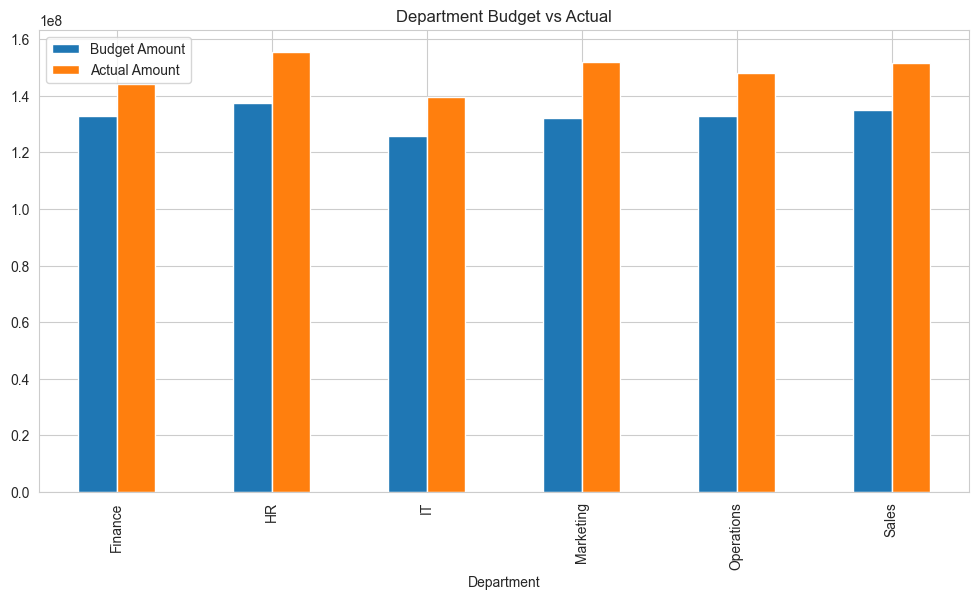

In [22]:
dept_summary[['Budget Amount','Actual Amount']].plot(
    kind='bar',
    figsize=(12,6)
)

plt.title("Department Budget vs Actual")
plt.show()

9. Category Analysis

In [23]:
category_summary = df.groupby('Category')[
    ['Budget Amount','Actual Amount','Variance']
].sum()

category_summary

,Budget Amount,Actual Amount,Variance
Category,,,
Infrastructure,128007938,141018280,13010342
Marketing,130247361,146615391,16368030
Salaries,127162015,147781233,20619218
Training,132399473,145010926,12611453
Travel,140209741,155272054,15062313
Utilities,138044486,155489736,17445250


10. Top 10 Overspending Areas

In [24]:
top_over = (
    df.groupby(['Department','Category'])['Variance']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_over

Department  Category 
Marketing   Training     5501558
            Travel       4134647
Operations  Salaries     4116403
Sales       Utilities    4067500
Operations  Utilities    3988056
IT          Salaries     3974415
HR          Training     3699628
Marketing   Marketing    3638120
Operations  Marketing    3621586
Marketing   Salaries     3510773
Name: Variance, dtype: int64

Visualization

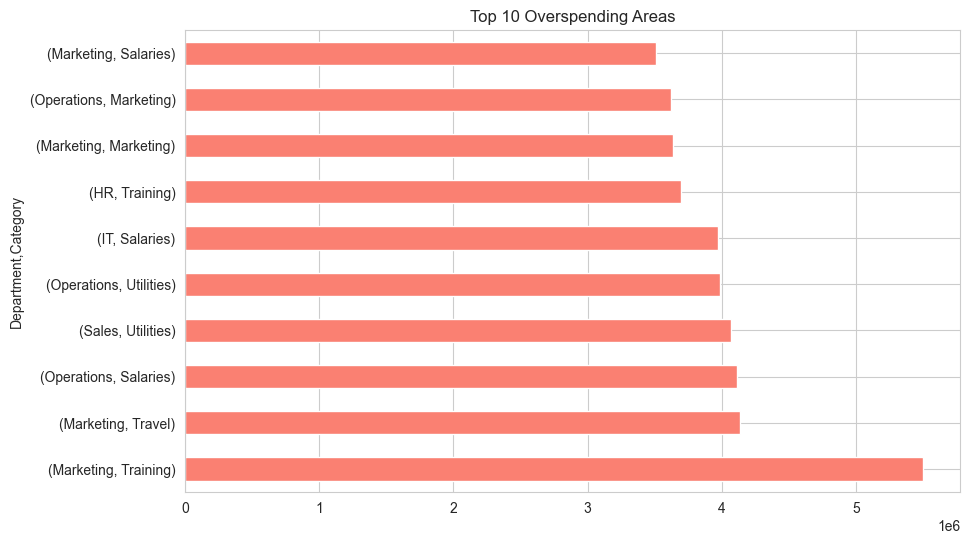

In [35]:
plt.figure(figsize=(10,6))

top_over.plot(kind='barh', color='salmon')

plt.title("Top 10 Overspending Areas")
plt.show()

11. Monthly Trend Analysis

In [36]:
monthly = df.groupby('Month')[
    ['Budget Amount','Actual Amount']
].sum()

monthly

,Budget Amount,Actual Amount
Month,,
April,66373367,77739447
August,68538617,76487387
December,67979857,77573305
February,56832212,64532936
January,67434477,74438865
July,70140163,79235012
June,67234895,71266099
March,63778210,73445092
May,70634101,78646771


Visualization

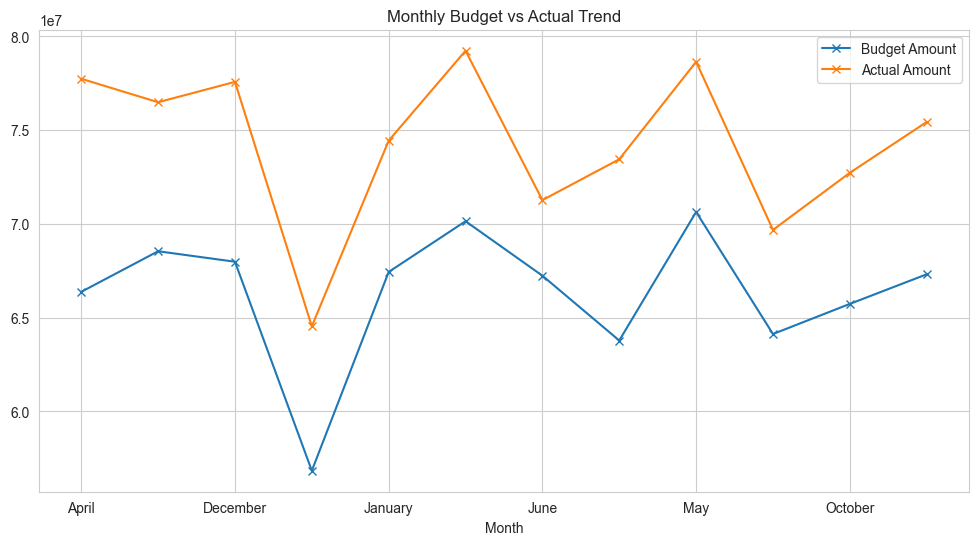

In [ ]:
monthly.plot(
    figsize=(12,6),
    marker='o'
)

plt.title("Monthly Budget vs Actual Trend")
plt.show()

12. Status Analysis

In [39]:
df['Status'].value_counts()

Status
Over Budget      5598
Within Budget    4412
Name: count, dtype: int64

Pie Chart

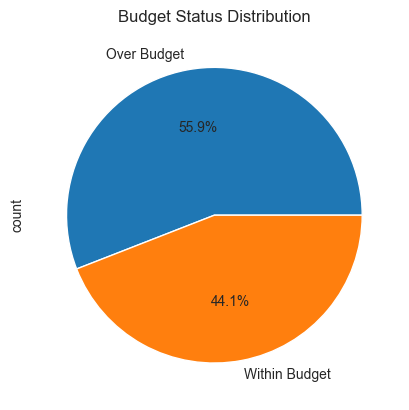

In [40]:
df['Status'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title("Budget Status Distribution")
plt.show()

13. Correlation Analysis

In [41]:
corr = df[
    ['Budget Amount',
     'Actual Amount',
     'Variance',
     'Variance %']
].corr()

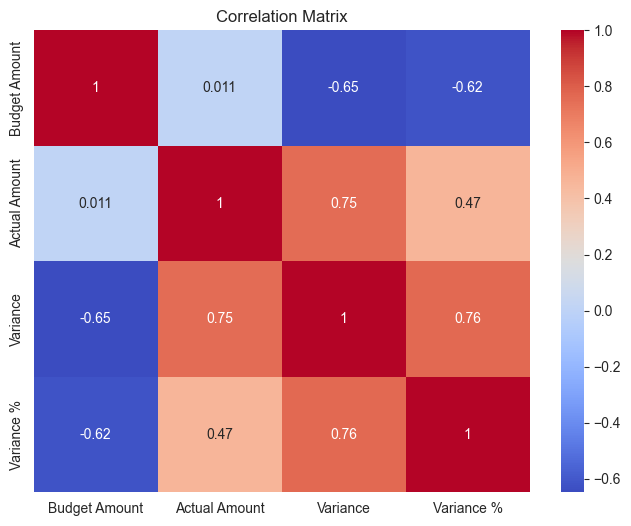

In [42]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Matrix")
plt.show()